<a href="https://colab.research.google.com/github/angiecognioulhanicq/Proyecto-integrador/blob/main/trabajo_final_utn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd

df = pd.read_csv('Datos_202606[1].csv')
print(df.head())
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

   periodo aseguradora  cant_parte_empleadora  cant_personas_trabaj_up   ciiu  \
0   202606  PREVENCION                      7                        7  14113   
1   202606   PROVINCIA                      1                        1  11211   
2   202606   PROVINCIA                      3                        3  14113   
3   202606  LA SEGUNDA                      1                        1  11211   
4   202606  LA SEGUNDA                      1                        1  16112   

    cuota_up  grupo  jurisdiccion_codigo  parte_empleadora_tipo  recaudada_up  \
0  1013579.0   14.0                    0                      3           0.0   
1   105548.0   11.0                    0                      3           0.0   
2   461735.0   14.0                    0                      3           0.0   
3    66880.0   11.0                    0                      3           0.0   
4    53664.0   16.0                    0                      3           0.0   

   remuneracion seccion ta

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [12]:
# Agrupar por aseguradora y sumar la remuneración
remuneracion_por_aseguradora = df.groupby('aseguradora')['remuneracion'].sum().reset_index()

# Mostrar el resultado ordenado de mayor a menor
remuneracion_por_aseguradora = remuneracion_por_aseguradora.sort_values(by='remuneracion', ascending=False)
display(remuneracion_por_aseguradora)

,aseguradora,remuneracion
4,PREVENCION,3.679374e+12
5,PROVINCIA,3.467281e+12
1,EXPERTA ART,2.099592e+12
0,ASOCIART,1.733966e+12
6,SWISS MEDICAL,1.456165e+12
2,FED. PATRONAL,1.182076e+12
3,LA SEGUNDA,1.139277e+12


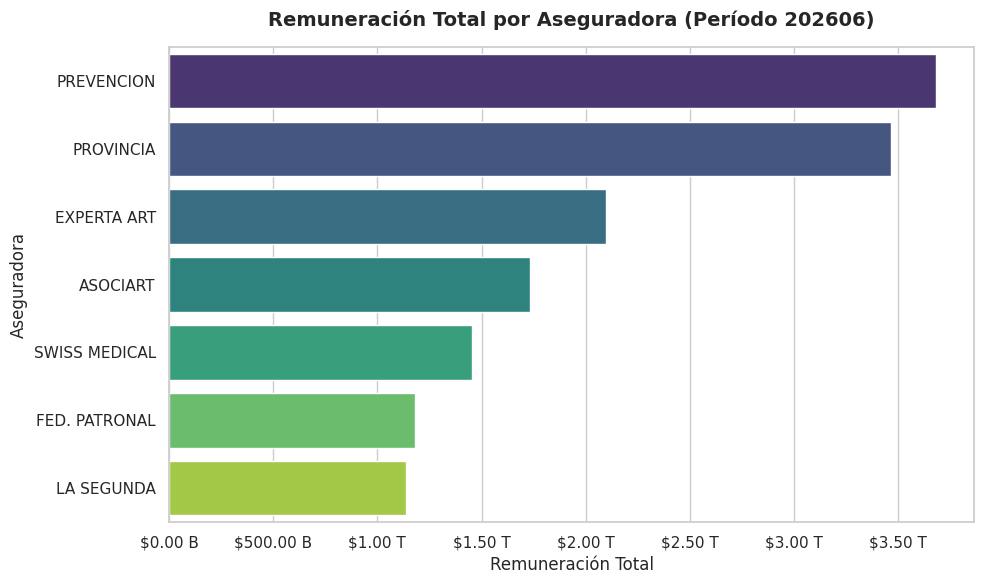

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configuramos el estilo y tamaño del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Creamos el gráfico de barras
ax = sns.barplot(
    x='remuneracion',
    y='aseguradora',
    data=remuneracion_por_aseguradora,
    palette='viridis',
    hue='aseguradora',
    legend=False
)

# Ajustamos títulos y etiquetas
plt.title('Remuneración Total por Aseguradora (Período 202606)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Remuneración Total', fontsize=12)
plt.ylabel('Aseguradora', fontsize=12)

# Ajustamos los límites y formato para evitar notación científica cruda
import matplotlib.ticker as ticker
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x*1e-12:.2f} T' if x >= 1e12 else f'${x*1e-9:.2f} B'))

plt.tight_layout()
plt.show()

In [15]:
# Calcular el promedio de remuneración agrupado por sección
promedio_remuneracion_seccion = df.groupby('seccion')['remuneracion'].mean().reset_index()

# Renombrar la columna para claridad
promedio_remuneracion_seccion.columns = ['seccion', 'promedio_remuneracion']

# Mostrar el resultado ordenado de mayor a menor promedio
promedio_remuneracion_seccion = promedio_remuneracion_seccion.sort_values(by='promedio_remuneracion', ascending=False)
display(promedio_remuneracion_seccion)

,seccion,promedio_remuneracion
14,O,1.755724e+09
3,D,5.121506e+08
1,B,4.807016e+08
15,P,2.859829e+08
4,E,2.078197e+08
10,K,1.987217e+08
9,J,1.831172e+08
7,H,1.094601e+08
2,C,1.048057e+08
5,F,9.933753e+07


In [16]:
import pandas as pd

# Agrupar por sección y aseguradora sumando la remuneración
recaudacion_seccion_aseg = df.groupby(['seccion', 'aseguradora'])['remuneracion'].sum().reset_index()

# Encontrar la aseguradora con la máxima remuneración para cada sección
idx_max = recaudacion_seccion_aseg.groupby('seccion')['remuneracion'].idxmax()
aseguradora_top_por_seccion = recaudacion_seccion_aseg.loc[idx_max].sort_values(by='remuneracion', ascending=False).reset_index(drop=True)

# Renombrar columnas para mayor claridad
aseguradora_top_por_seccion.columns = ['Sección', 'Aseguradora Líder', 'Remuneración Total']

display(aseguradora_top_por_seccion)

,Sección,Aseguradora Líder,Remuneración Total
0,O,PROVINCIA,1.396856e+12
1,C,PREVENCION,6.433734e+11
2,G,PREVENCION,4.706248e+11
3,H,PROVINCIA,2.816941e+11
4,K,PREVENCION,2.310973e+11
5,P,PREVENCION,2.156932e+11
6,B,EXPERTA ART,2.007686e+11
7,F,PREVENCION,1.986536e+11
8,M,SWISS MEDICAL,1.793071e+11
9,J,EXPERTA ART,1.692696e+11


In [17]:
# Agrupar por sección y aseguradora sumando la cantidad de empleadores
empleadores_seccion_aseg = df.groupby(['seccion', 'aseguradora'])['cant_parte_empleadora'].sum().reset_index()

# Encontrar la aseguradora con más empleadores por sección
idx_max_emp = empleadores_seccion_aseg.groupby('seccion')['cant_parte_empleadora'].idxmax()
aseguradora_top_empleadores = empleadores_seccion_aseg.loc[idx_max_emp].sort_values(by='cant_parte_empleadora', ascending=False).reset_index(drop=True)

# Renombrar columnas para claridad
aseguradora_top_empleadores.columns = ['Sección', 'Aseguradora con más Empleadores', 'Total Empleadores']

display(aseguradora_top_empleadores)

,Sección,Aseguradora con más Empleadores,Total Empleadores
0,G,PREVENCION,39179
1,A,PREVENCION,16459
2,C,PREVENCION,12292
3,S,EXPERTA ART,10590
4,H,PREVENCION,9676
5,M,PREVENCION,7802
6,I,PREVENCION,6234
7,F,PREVENCION,6210
8,Q,PREVENCION,5980
9,L,ASOCIART,4626


In [18]:
# Agrupar por jurisdicción sumando la cantidad de personas trabajadoras aseguradas
asegurados_por_jurisdiccion = df.groupby('jurisdiccion_codigo')['cant_personas_trabaj_up'].sum().reset_index()

# Ordenar de mayor a menor
asegurados_por_jurisdiccion = asegurados_por_jurisdiccion.sort_values(by='cant_personas_trabaj_up', ascending=False).reset_index(drop=True)

# Renombrar columnas para claridad
asegurados_por_jurisdiccion.columns = ['Jurisdicción Código', 'Total Asegurados']

display(asegurados_por_jurisdiccion.head(10))

,Jurisdicción Código,Total Asegurados
0,1,2174187
1,0,1619209
2,12,554155
3,3,531175
4,7,376948
5,9,222227
6,14,174675
7,4,151333
8,10,150593
9,20,149031


In [19]:
import pandas as pd

try:
    # Intentamos cargar el archivo de dimensiones de jurisdicción
    dim_jurisdiccion = pd.read_excel('Dim_JURISDICCION[1].xlsx')
    print("Archivo de dimensiones de jurisdicción cargado con éxito. Columnas:", dim_jurisdiccion.columns.tolist())

    # Unir con nuestros resultados de asegurados
    # Nota: Ajustaremos los nombres de las columnas para realizar la unión adecuadamente
    # Buscaremos una columna que represente el código en el archivo de dimensión
    col_codigo = [c for c in dim_jurisdiccion.columns if 'codigo' in c.lower() or 'id' in c.lower() or 'jurisdiccion' in c.lower()][0]

    asegurados_con_nombre = pd.merge(
        asegurados_por_jurisdiccion,
        dim_jurisdiccion,
        left_on='Jurisdicción Código',
        right_on=col_codigo,
        how='left'
    )

    # Mostrar el resultado final ordenado
    display(asegurados_con_nombre[['Jurisdicción Código', col_codigo + '_DESC' if col_codigo + '_DESC' in asegurados_con_nombre.columns else dim_jurisdiccion.columns[1], 'Total Asegurados']].head(10))
except Exception as e:
    # En caso de que el nombre del archivo sea ligeramente diferente, listamos los archivos para ayudar al usuario
    import os
    print("No se pudo cargar de forma automática. Error:", e)
    print("Archivos disponibles en el directorio actual:", [f for f in os.listdir('.') if 'jurisdiccion' in f.lower() or 'xlsx' in f.lower()])

Archivo de dimensiones de jurisdicción cargado con éxito. Columnas: ['JURISDICCION_CODIGO', 'JURISDICCION_DESC', 'REGION']


,Jurisdicción Código,JURISDICCION_DESC,Total Asegurados
0,1,Buenos Aires,2174187
1,0,C.A.B.A.,1619209
2,12,Santa Fe,554155
3,3,Cordoba,531175
4,7,Mendoza,376948
5,9,Salta,222227
6,14,Tucuman,174675
7,4,Corrientes,151333
8,10,San Juan,150593
9,20,Neuquen,149031


In [21]:
# Unir el DataFrame principal (df) con las dimensiones de jurisdicción especificando los nombres de columna correctos
df_con_region = pd.merge(
    df,
    dim_jurisdiccion,
    left_on='jurisdiccion_codigo',
    right_on='JURISDICCION_CODIGO',
    how='left'
)

# Agrupar por REGION y sumar la cantidad de personas aseguradas
asegurados_por_region = df_con_region.groupby('REGION')['cant_personas_trabaj_up'].sum().reset_index()

# Ordenar los resultados de mayor a menor
asegurados_por_region = asegurados_por_region.sort_values(by='cant_personas_trabaj_up', ascending=False).reset_index(drop=True)

# Renombrar columnas para mayor claridad
asegurados_por_region.columns = ['Región', 'Total Asegurados']

display(asegurados_por_region)

,Región,Total Asegurados
0,METROPOLITANA,3793396
1,CENTRO,1269136
2,CUYO,631275
3,NOA,585213
4,PATAGONIA,471375
5,NEA,391115


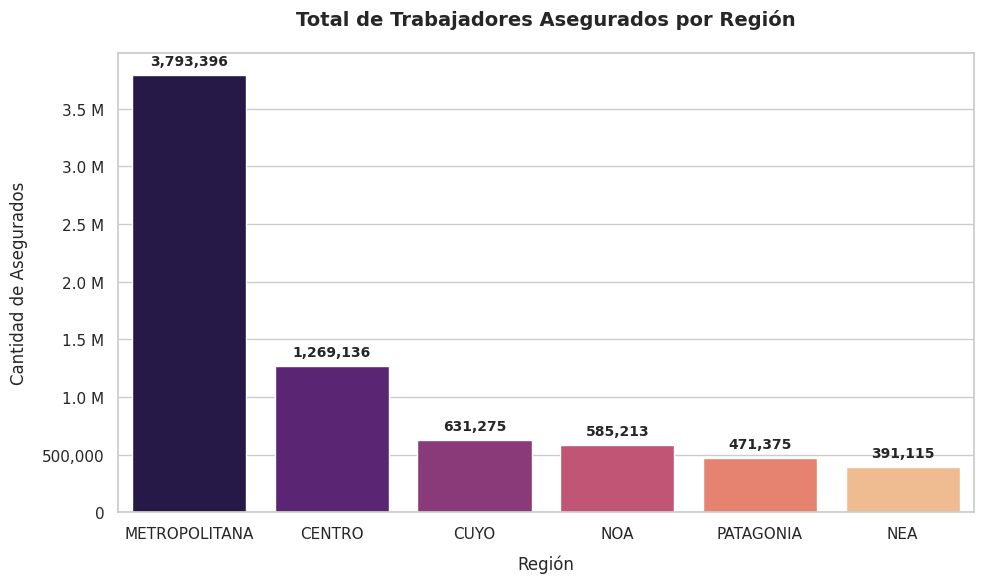

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Configurar el estilo y el tamaño del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el gráfico de barras
ax = sns.barplot(
    x='Región',
    y='Total Asegurados',
    data=asegurados_por_region,
    palette='magma',
    hue='Región',
    legend=False
)

# Añadir etiquetas con el valor exacto sobre cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:,.0f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 5),
                    textcoords='offset points')

# Título y etiquetas de ejes
plt.title('Total de Trabajadores Asegurados por Región', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Región', fontsize=12, labelpad=10)
plt.ylabel('Cantidad de Asegurados', fontsize=12, labelpad=10)

# Dar formato al eje Y para evitar notación científica y hacerlo más legible (en millones)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x*1e-6:.1f} M' if x >= 1e6 else f'{x:,.0f}'))

plt.tight_layout()
plt.show()